# 01 · Exploratory analysis: ULB credit card fraud

**Dataset.** 284,807 card transactions made by European cardholders over two days in
September 2013, released by the Machine Learning Group of the Université Libre de
Bruxelles (ULB). 492 of them are fraud (473 after removing duplicates).

**What makes it unusual.** For confidentiality, 28 of the 30 inputs (`V1` to `V28`) are
the output of a **PCA** (principal component analysis). PCA rotates the original
features into new, uncorrelated axes ordered by how much variance they explain. We lose
the meaning of each column ("V14" is not "merchant category"), but the information
survives. Only `Time` (seconds since the first transaction) and `Amount` are left raw.

**Questions for this notebook**
1. How imbalanced is the problem, and why does that change how we evaluate models?
2. Do amount and time of day differ between fraud and legit transactions?
3. Which anonymised features separate the two classes, and how?
4. Do frauds form a distinct region of feature space? That decides whether
   unsupervised anomaly detection (notebook 03) has a chance.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from fraudkit.data import load_ulb
from fraudkit.plotting import (
    CLASS_COLORS, CLASS_NAMES, DIVERGING, INK_2, MUTED, SERIES,
    class_hist, class_legend, finish, label_bars, set_style,
)

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Load and clean

`load_ulb` downloads the data from Kaggle on first use, sorts it by time and adds two
derived columns: `Hour` (time of day) and `LogAmount`.

**Duplicates.** The raw file has exact duplicate rows. We drop them *before* any split.
If one copy landed in training and the other in test, the model would be scored on rows
it has effectively memorised, a form of **data leakage** that inflates results.

In [2]:
raw = load_ulb(drop_duplicates=False)
df = load_ulb()
dup_fraud = raw.duplicated() & (raw.Class == 1)
print(f"raw rows: {len(raw):,}   after dropping duplicates: {len(df):,}   "
      f"(removed {len(raw) - len(df):,}, of which {dup_fraud.sum()} fraud)")
print(f"missing values: {df.isna().sum().sum()}")
df.head()

raw rows: 284,807   after dropping duplicates: 283,726   (removed 1,081, of which 19 fraud)
missing values: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Class,Hour,LogAmount
0,0.000,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,...,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.620,0,0.000,5.015
1,0.000,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,...,0.101,-0.340,0.167,0.126,-0.009,0.015,2.690,0,0.000,1.306
2,1.000,-1.358,-1.340,1.773,0.380,-0.503,1.800,0.791,0.248,-1.515,...,0.909,-0.689,-0.328,-0.139,-0.055,-0.060,378.660,0,0.000,5.939
3,1.000,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,...,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.500,0,0.000,4.824
4,2.000,-1.158,0.878,1.549,0.403,-0.407,0.096,0.593,-0.271,0.818,...,-0.137,0.141,-0.206,0.502,0.219,0.215,69.990,0,0.001,4.263


## 2. Class imbalance: the defining property of fraud data

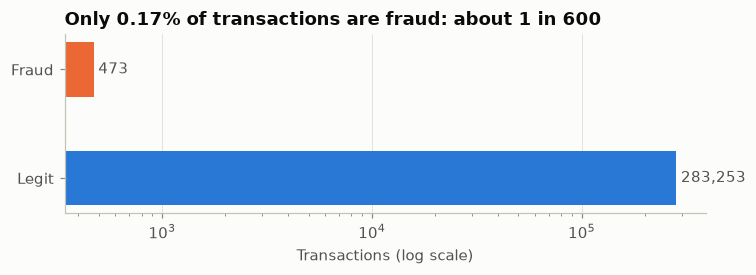

In [3]:
counts = df.Class.value_counts().sort_index()
rate = df.Class.mean()

fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh([CLASS_NAMES[c] for c in counts.index], counts.values,
               color=[CLASS_COLORS[c] for c in counts.index], height=0.5)
label_bars(ax, bars, fmt="{:,.0f}", horizontal=True)
ax.set_xscale("log")
ax.set_xlabel("Transactions (log scale)")
ax.set_title(f"Only {rate:.2%} of transactions are fraud: about 1 in {1 / rate:,.0f}")
ax.grid(axis="y", visible=False)
finish(fig)

**Why accuracy is useless here.** A "model" that labels every transaction as legit
scores **99.83 % accuracy** and catches zero fraud. With imbalance this extreme we need
metrics that focus on the rare class:

* **Precision**: of the transactions we flag, what share is really fraud? (Cost of
  analyst time and annoyed customers.)
* **Recall**: of all fraud, what share do we flag? (Money saved.)
* **PR-AUC** (area under the precision–recall curve, also called *average precision*)
  summarises the trade-off across all thresholds. A random model scores roughly the
  fraud rate (≈ 0.0017), so it is far more demanding than ROC-AUC, where random is 0.5
  and the huge pool of easy negatives makes most models look excellent.

We will use PR-AUC as the main metric from notebook 02 on.

## 3. Transaction amount

In [4]:
print(df.groupby("Class")["Amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.95])
        .rename(index=CLASS_NAMES))

            count    mean     std   min   25%    50%     75%     95%  \
Class                                                                  
Legit 283,253.000  88.414 250.379 0.000 5.670 22.000  77.460 365.000   
Fraud     473.000 123.872 260.211 0.000 1.000  9.820 105.890 655.820   

             max  
Class             
Legit 25,691.160  
Fraud  2,125.870  


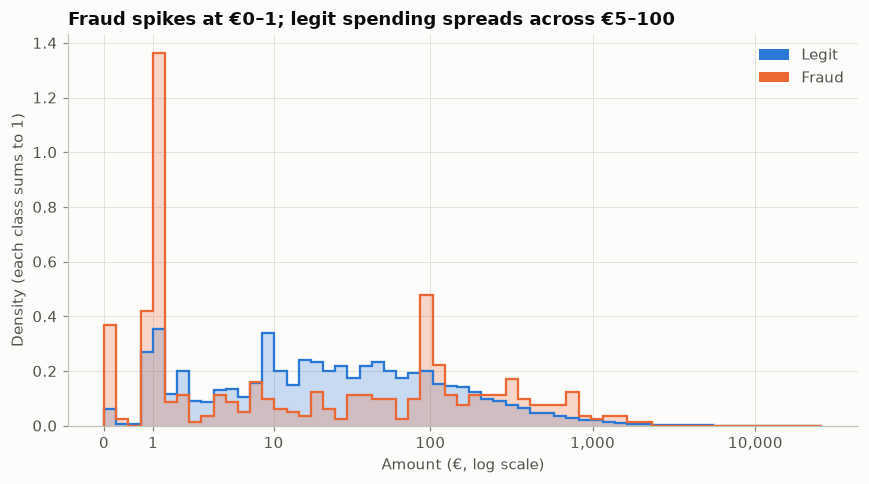

In [5]:
fig, ax = plt.subplots()
bins = np.linspace(0, df.LogAmount.max(), 60)
class_hist(ax, df.LogAmount, df.Class, bins)
ticks = [0, 1, 10, 100, 1_000, 10_000]
ax.set_xticks(np.log1p(ticks), [f"{t:,}" for t in ticks])
ax.set_xlabel("Amount (€, log scale)")
ax.set_ylabel("Density (each class sums to 1)")
ax.set_title("Fraud spikes at €0–1; legit spending spreads across €5–100")
class_legend(ax)
finish(fig)

Each class is normalised to its own total (`density=True`); otherwise the 492 frauds
would be invisible next to 283k legit transactions.

**Reading it.** About a quarter of frauds are €1 or less, including a group at exactly
€0. A common explanation is **card testing**: fraudsters check that a stolen card works
with a tiny charge before spending more. The median fraud (≈ €10) is half the median
legit transaction (€22), yet the fraud *mean* is higher: a long tail of large frauds.
There is also a second spike just under €100, a price point fraudsters seem to favour.
Amount alone is a weak signal, so the model will need it in combination with other
features.

## 4. Time of day

The data covers two days, so `Hour` (seconds modulo one day) shows the daily cycle.
Volume and fraud **rate** go on two separate charts. Putting them on one chart with two
y-axes would make their relationship look like whatever the axis scaling suggests.

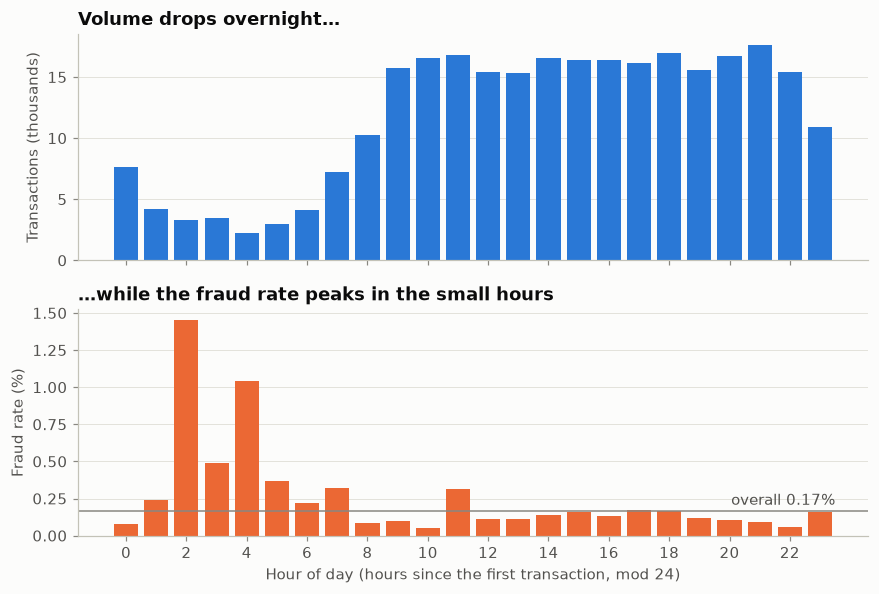

In [6]:
df["HourBin"] = df.Hour.astype(int)
by_hour = df.groupby("HourBin").agg(n=("Class", "size"), fraud=("Class", "sum"))
by_hour["rate"] = by_hour.fraud / by_hour.n

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
ax1.bar(by_hour.index, by_hour.n / 1_000, color=CLASS_COLORS[0], width=0.8)
ax1.set_ylabel("Transactions (thousands)")
ax1.set_title("Volume drops overnight…")
ax2.bar(by_hour.index, by_hour.rate * 100, color=CLASS_COLORS[1], width=0.8)
ax2.axhline(rate * 100, color=MUTED, lw=1)
ax2.annotate(f"overall {rate:.2%}", (23.5, rate * 100), xytext=(0, 4), textcoords="offset points",
             ha="right", color=INK_2)
ax2.set_ylabel("Fraud rate (%)")
ax2.set_xlabel("Hour of day (hours since the first transaction, mod 24)")
ax2.set_title("…while the fraud rate peaks in the small hours")
ax2.set_xticks(range(0, 24, 2))
for a in (ax1, ax2):
    a.grid(axis="x", visible=False)
finish(fig)

**Reading it.** Fraudsters do not sleep when cardholders do. Between roughly 2 and 4 am
the fraud *count* is lower, but its *share* of transactions is several times the average.
We keep `Hour` as a feature. We don't know the time zone, and two days is too short to
learn weekly patterns, so we won't read more into it than that.

## 5. Which anonymised features separate fraud from legit?

For each feature we run a **two-sample Kolmogorov–Smirnov test**. Its statistic *D* is
the largest gap between the two classes' cumulative distributions: 0 means identical
distributions, 1 means perfectly separated. It makes no assumption about the
distribution's shape and ignores scale, so it suits a quick screen like this.

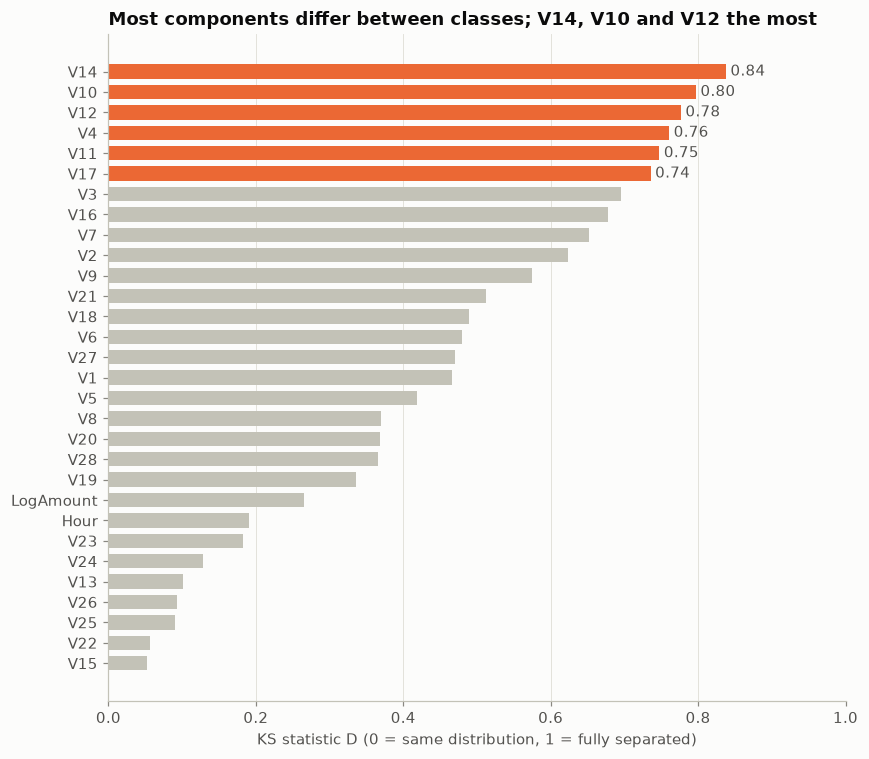

In [7]:
features = [f"V{i}" for i in range(1, 29)] + ["LogAmount", "Hour"]
fraud, legit = df[df.Class == 1], df[df.Class == 0]
ks = pd.Series({f: ks_2samp(fraud[f], legit[f]).statistic for f in features}).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
top = ks.index[-6:]
bars = ax.barh(ks.index, ks.values, height=0.7,
               color=[SERIES[1] if f in top else "#c3c2b7" for f in ks.index])
label_bars(ax, bars[-6:], fmt="{:.2f}", horizontal=True)
ax.set_xlabel("KS statistic D (0 = same distribution, 1 = fully separated)")
ax.set_title("Most components differ between classes; V14, V10 and V12 the most")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1)
finish(fig)

Over half of the components have *D* > 0.5: the signal is strong and spread out. The
top six are **V14, V10, V12, V4, V11 and V17**. A low *D* doesn't mean a feature is
useless. It can still matter in combination with others, which tree models
(notebook 02) can pick up. `LogAmount` and `Hour` rank low on their own.

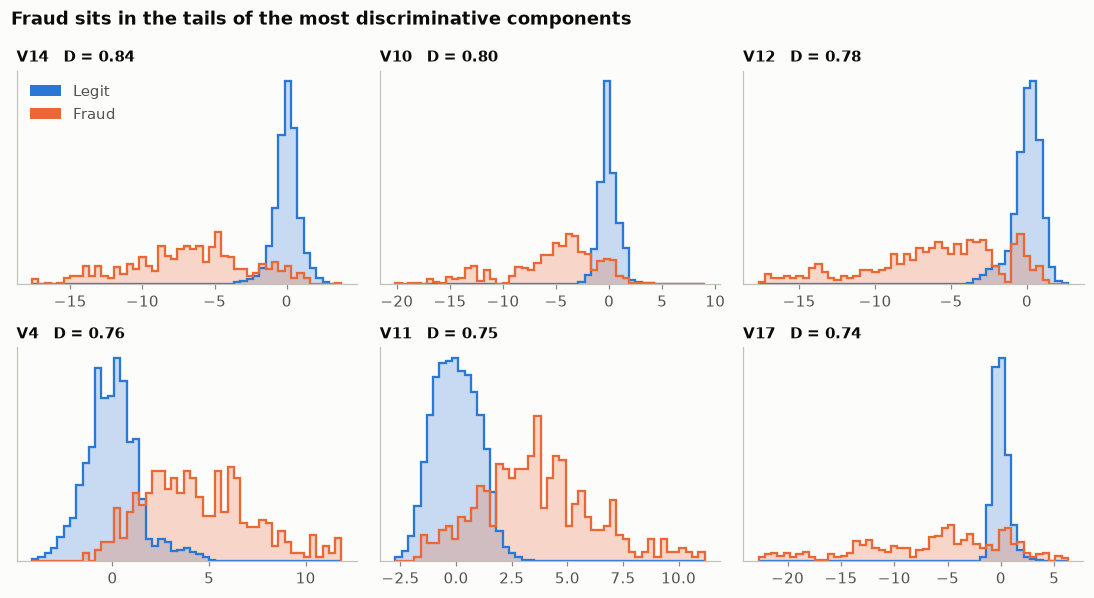

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5))
for ax, f in zip(axes.flat, ks.index[::-1][:6]):
    # Range covers 98% of fraud and 99.8% of legit; the few rows outside are left out
    # (not clipped to the edge, which would draw fake spikes there).
    lo = min(fraud[f].quantile(0.01), legit[f].quantile(0.001))
    hi = max(fraud[f].quantile(0.99), legit[f].quantile(0.999))
    class_hist(ax, df[f], df.Class, np.linspace(lo, hi, 50))
    ax.set_title(f"{f}   D = {ks[f]:.2f}", fontsize=10)
    ax.set_yticks([])
    ax.grid(False)
class_legend(axes[0, 0], loc="upper left")
fig.suptitle("Fraud sits in the tails of the most discriminative components",
             x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** Legit transactions sit in a narrow peak around 0, which is where PCA
centres the data. Fraud is shifted and much more spread out: towards strongly negative
values of V14, V10, V12 and V17 and positive values of V4 and V11. The shift is large but the overlap is not
zero, so no single threshold on one feature will catch everything.

## 6. Correlation structure: frauds move together

PCA components are uncorrelated **over the whole dataset** by construction. Inside the
fraud class, however, they can be strongly correlated. A strong correlation there would
mean frauds follow a consistent multivariate *pattern*, which is good news for any model.

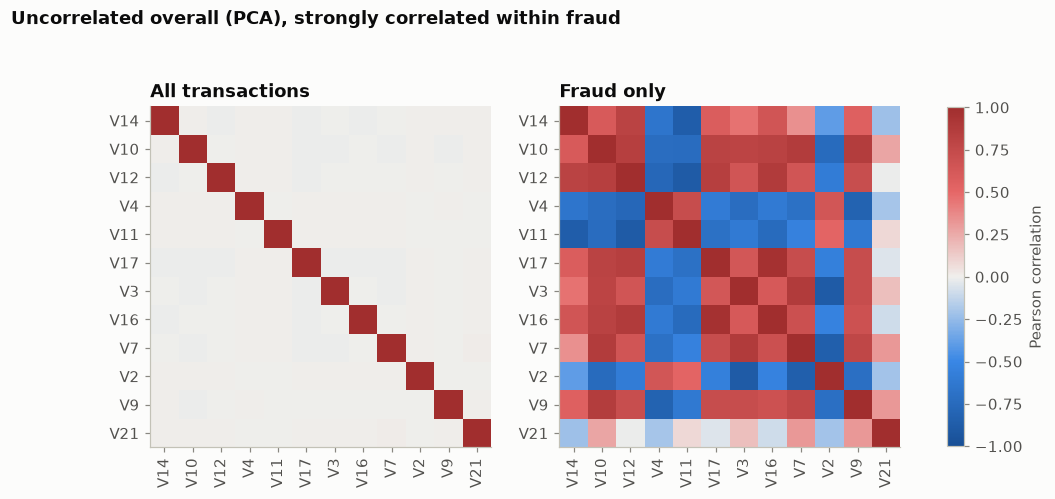

In [9]:
top12 = list(ks.index[::-1][:12])
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (title, sub) in zip(axes, [("All transactions", df), ("Fraud only", fraud)]):
    corr = sub[top12].corr()
    im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(top12)), top12, rotation=90)
    ax.set_yticks(range(len(top12)), top12)
    ax.set_title(title)
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="Pearson correlation")
fig.suptitle("Uncorrelated overall (PCA), strongly correlated within fraud",
             x=0.01, ha="left", fontweight="bold")
plt.show()

**Reading it.** On the left, the near-zero off-diagonal values are what PCA guarantees.
On the right, many discriminative components move together within fraud: when V14 is very
negative, V12, V10 and V17 tend to be too. Frauds share a common signature.

## 7. Do frauds form their own region? A t-SNE map

**t-SNE** squeezes the 30-dimensional data into 2-D while trying to keep each point's
nearest neighbours nearby. Distances *between* far-apart clusters are not meaningful, but
local grouping is. Running it on all 283k rows would be slow, so we use every fraud plus
a random 6,000 legit transactions. Features are standardised first so that `Amount`'s
scale doesn't dominate the distances.

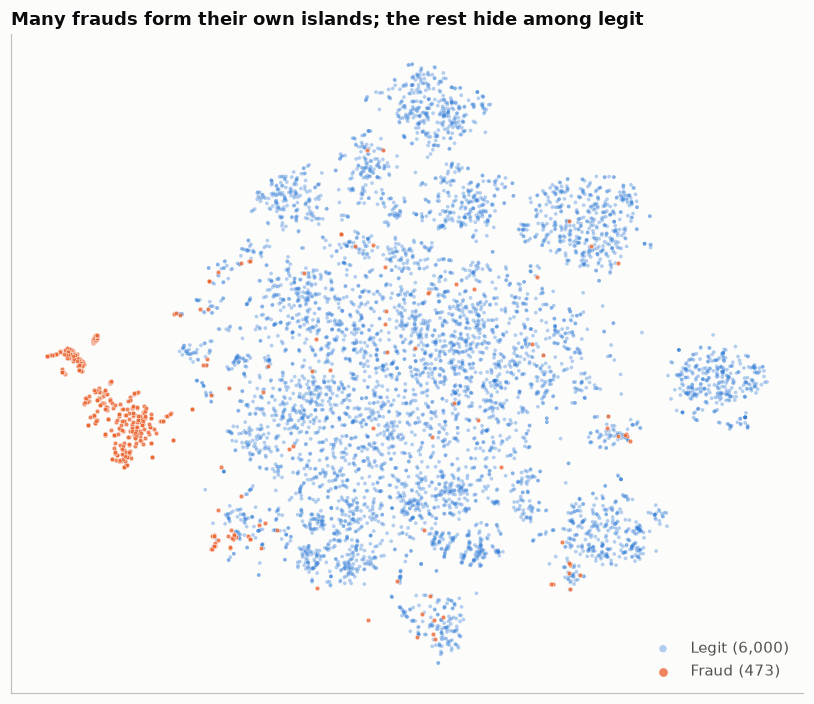

In [10]:
sample = pd.concat([fraud, legit.sample(6_000, random_state=0)])
X = StandardScaler().fit_transform(sample[features])
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=0).fit_transform(X)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for c in (0, 1):
    m = sample.Class.values == c
    ax.scatter(emb[m, 0], emb[m, 1], s=9 if c else 6, alpha=0.8 if c else 0.35,
               color=CLASS_COLORS[c], edgecolor="white" if c else "none", linewidth=0.3,
               label=f"{CLASS_NAMES[c]} ({m.sum():,})")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(loc="lower right", markerscale=2)
ax.set_title("Many frauds form their own islands; the rest hide among legit")
finish(fig)

To put a number on "islands vs. hidden", we look at each fraud's 15 nearest neighbours in
the **original standardised space** (not the t-SNE map, whose geometry is distorted). If
most of them are frauds too, the fraud sits in a fraud cluster.

Caveat: the sample keeps 1 legit in 47, so the true neighbourhoods are far more legit
than this. Treat the figure as a relative measure, not a deployable one.

In [11]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=16).fit(X)
_, idx = nn.kneighbors(X[sample.Class.values == 1])
fraud_share = sample.Class.values[idx[:, 1:]].mean(axis=1)   # column 0 is the point itself
print(f"frauds whose neighbourhood is mostly fraud: {(fraud_share > 0.5).mean():.0%}")
print(f"frauds with no fraud among 15 neighbours:  {(fraud_share == 0).mean():.0%}")

frauds whose neighbourhood is mostly fraud: 79%
frauds with no fraud among 15 neighbours:  7%


**Reading it.** A large share of frauds forms compact islands away from the legit mass
(left of the map). Those are the "easy" frauds, and even an unsupervised detector should
flag them. In the neighbour count above, about 4 in 5 frauds live in a mostly-fraud
neighbourhood, while about 7 % have **no** fraud among their 15 nearest neighbours.
Those frauds look normal in this feature space and will set the ceiling on recall for
every model.

## 8. Takeaways for modelling

| Finding | Consequence |
|---|---|
| 0.17 % fraud rate | Use PR-AUC and recall at a fixed alert budget, never accuracy. Use stratification or class weights. |
| 1,081 duplicate rows | Drop before splitting to avoid leakage (done in `load_ulb`). |
| Data spans 48 hours in time order | Split **by time** (train on the past, test on the future), not at random. |
| Strong, widespread signal; components correlated within fraud | Even a linear model should do well. Trees can exploit the interactions. |
| ~80 % of frauds in fraud neighbourhoods, ~7 % fully hidden among legit | Anomaly detection is worth testing (notebook 03), but labels should win on the "hidden" frauds. |
| Small fraud amounts (card testing) | `Amount` matters less than its size suggests. The cost analysis in notebook 04 should weight frauds by amount. |

**Next:** [02 · Imbalance strategies](02_imbalance_strategies.ipynb)